In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv ("all_upwork_jobs_2024-02-07-2024-03-24.csv")

In [3]:
df.shape


(244828, 8)

In [4]:
df.head()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244828 entries, 0 to 244827
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   title           244827 non-null  object 
 1   link            244827 non-null  object 
 2   published_date  244828 non-null  object 
 3   is_hourly       244828 non-null  bool   
 4   hourly_low      102422 non-null  float64
 5   hourly_high     98775 non-null   float64
 6   budget          103891 non-null  float64
 7   country         239751 non-null  object 
dtypes: bool(1), float64(3), object(4)
memory usage: 13.3+ MB


In [6]:
df.describe()

,hourly_low,hourly_high,budget
count,102422.000000,98775.000000,103891.000000
mean,17.339644,41.970610,911.473564
std,18.140065,47.850892,15729.738834
min,3.000000,3.000000,5.000000
25%,8.000000,20.000000,25.000000
50%,15.000000,30.000000,100.000000
75%,20.000000,50.000000,300.000000
max,998.000000,999.000000,1000000.000000


In [7]:
df.columns

Index(['title', 'link', 'published_date', 'is_hourly', 'hourly_low',
       'hourly_high', 'budget', 'country'],
      dtype='object')

In [8]:
#  Check Duplicate Records

print("Total Duplicate Rows:", df.duplicated().sum())
print("Total Rows:", len(df))

Total Duplicate Rows: 0
Total Rows: 244828


In [9]:
# Step 31: Missing Values by Payment Type

print(
    df.groupby("is_hourly")[
        ["hourly_low", "hourly_high", "budget"]
    ].apply(lambda group: group.isnull().sum())
)

           hourly_low  hourly_high  budget
is_hourly                                 
False          103891       103891       0
True            38515        42162  140937


In [10]:
df.isnull().sum()

title                  1
link                   1
published_date         0
is_hourly              0
hourly_low        142406
hourly_high       146053
budget            140937
country             5077
dtype: int64

In [11]:
(df.isnull().sum() / len(df) * 100).round(2)

title              0.00
link               0.00
published_date     0.00
is_hourly          0.00
hourly_low        58.17
hourly_high       59.66
budget            57.57
country            2.07
dtype: float64

In [12]:
df["is_hourly"].value_counts()

is_hourly
True     140937
False    103891
Name: count, dtype: int64

In [13]:
df.groupby("is_hourly")[["hourly_low", "hourly_high", "budget"]].count()

,hourly_low,hourly_high,budget
is_hourly,,,
False,0,0,103891
True,102422,98775,0


In [14]:
# Step 3: Average Hourly Rate Analysis

df[df["is_hourly"] == True][["hourly_low", "hourly_high"]].mean()

hourly_low     17.339644
hourly_high    41.970610
dtype: float64

In [15]:
# Step 4: Most Common Job Titles

df["title"].value_counts().head(10)

title
Social Media Manager    419
Virtual Assistant       339
Logo Design             311
Video Editor            298
Graphic Designer        292
Logo design             173
Logo Designer           142
Full Stack Developer    136
Website Development     129
Appointment Setter      125
Name: count, dtype: int64

In [16]:
# Step 5: Normalize Job Titles

df["title"] = df["title"].str.lower()

df["title"].value_counts().head(10)

title
social media manager    509
logo design             490
video editor            413
virtual assistant       408
graphic designer        367
youtube video editor    181
lead generation         176
full stack developer    172
logo designer           171
data entry              169
Name: count, dtype: int64

In [17]:
# Step 6: Job Title vs Average Hourly Rates

df[df["is_hourly"] == True].groupby("title")[["hourly_low", "hourly_high"]].mean().sort_values(by="hourly_high", ascending=False).head(10)

,hourly_low,hourly_high
title,,
jobpost for automatescale,25.0,999.0
freelancing - support work / attractive pay per hour\ntime : 4hrs daily between 7pm to 4 am,600.0,999.0
intellij security service app development,3.0,999.0
moda app,25.0,999.0
day trader / option trader needed,25.0,999.0
moodle plugin development and system admin,3.0,999.0
video actor,35.0,999.0
mlm expert needed,5.0,999.0
dropshipping sourcing agent,10.0,999.0


In [18]:
# Step 7: Check Highest Hourly Rates

df[df["is_hourly"] == True][["hourly_low", "hourly_high"]].sort_values(by="hourly_high", ascending=False).head(10)

,hourly_low,hourly_high
49964,100.0,999.0
116586,25.0,999.0
144728,600.0,999.0
155598,10.0,999.0
219786,32.0,999.0
51604,100.0,999.0
241364,200.0,999.0
205388,8.0,999.0
205410,6.0,999.0
92579,25.0,999.0


In [19]:
# Step 7: Job Title vs Average Hourly Rates

df[df["is_hourly"] == True].groupby("title")[["hourly_low", "hourly_high"]].mean().sort_values(by="hourly_high", ascending=False).head(10).reset_index()

,title,hourly_low,hourly_high
0,jobpost for automatescale,25.0,999.0
1,freelancing - support work / attractive pay pe...,600.0,999.0
2,intellij security service app development,3.0,999.0
3,moda app,25.0,999.0
4,day trader / option trader needed,25.0,999.0
5,moodle plugin development and system admin,3.0,999.0
6,video actor,35.0,999.0
7,mlm expert needed,5.0,999.0
8,dropshipping sourcing agent,10.0,999.0
9,commission based sales representative (make th...,3.0,999.0


In [20]:
# Step 8: Check Hourly Rates Below 999

df[
    (df["is_hourly"] == True) &
    (df["hourly_high"] < 999)
][["title", "hourly_low", "hourly_high"]].head(10)


,title,hourly_low,hourly_high
2,smma bubble app,10.0,30.0
7,need portuguese writers who can understand and...,7.0,22.0
13,urgent: fix emails not working on discourse in...,40.0,75.0
15,web3 full-stack developer,30.0,50.0
18,"website design, ui/ux design",12.0,30.0
19,customer service,4.0,8.0
21,report analysis,15.0,30.0
24,linkedin ads coach,15.0,50.0
27,capcut genius,6.0,15.0
29,social media pro to write and post to instagram,5.0,15.0


In [21]:
# Step 9: Developer Jobs Average Hourly Rates

df[
    (df["is_hourly"] == True) &
    (df["title"].str.contains("developer", na=False)) &
    (df["hourly_high"] < 999)
][["hourly_low", "hourly_high"]].mean()

hourly_low     19.232633
hourly_high    40.085925
dtype: float64

In [22]:
# Step 10: Count Developer Jobs with Valid Hourly Rates

df[
    (df["is_hourly"] == True) &
    (df["title"].str.contains("developer", na=False)) &
    (df["hourly_high"] < 999)
].shape[0]

7716

In [23]:
# Step 11: Designer Jobs Average Hourly Rates

df[
    (df["is_hourly"] == True) &
    (df["title"].str.contains("designer", na=False)) &
    (df["hourly_high"] < 999)
][["hourly_low", "hourly_high"]].mean()

hourly_low     17.271434
hourly_high    38.456254
dtype: float64

In [24]:
# Step 12: Count Designer Jobs with Valid Hourly Rates

df[
    (df["is_hourly"] == True) &
    (df["title"].str.contains("designer", na=False)) &
    (df["hourly_high"] < 999)
].shape[0]

5692

In [25]:
# Step 13: Compare Developer vs Designer Hourly Rates

developer = df[
    (df["is_hourly"] == True) &
    (df["title"].str.contains("developer", na=False)) &
    (df["hourly_high"] < 999)
]

designer = df[
    (df["is_hourly"] == True) &
    (df["title"].str.contains("designer", na=False)) &
    (df["hourly_high"] < 999)
]

comparison = pd.DataFrame({
    "Job Category": ["Developer", "Designer"],
    "Job Count": [len(developer), len(designer)],
    "Average Hourly Low": [
        developer["hourly_low"].mean(),
        designer["hourly_low"].mean()
    ],
    "Average Hourly High": [
        developer["hourly_high"].mean(),
        designer["hourly_high"].mean()
    ]
})

print(comparison.round(2))

  Job Category  Job Count  Average Hourly Low  Average Hourly High
0    Developer       7716               19.23                40.09
1     Designer       5692               17.27                38.46


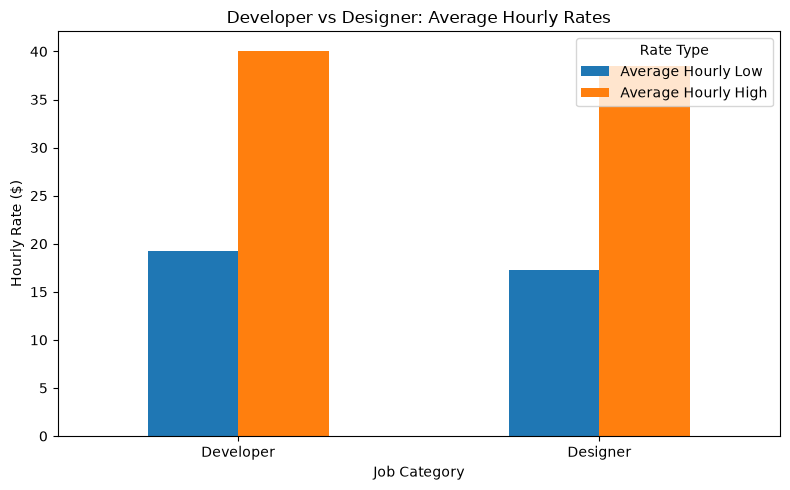

In [26]:
# Step 14: Visualize Developer vs Designer Hourly Rates

import matplotlib.pyplot as plt

comparison.plot(
    x="Job Category",
    y=["Average Hourly Low", "Average Hourly High"],
    kind="bar",
    figsize=(8, 5)
)

plt.title("Developer vs Designer: Average Hourly Rates")
plt.xlabel("Job Category")
plt.ylabel("Hourly Rate ($)")
plt.xticks(rotation=0)
plt.legend(title="Rate Type")
plt.tight_layout()
plt.show()

In [27]:
# Step 15: Analyze More Job Categories

keywords = [
    "developer",
    "designer",
    "writer",
    "marketing",
    "data entry",
    "virtual assistant"
]

results = []

for keyword in keywords:
    jobs = df[
        (df["is_hourly"] == True) &
        (df["title"].str.contains(keyword, na=False)) &
        (df["hourly_high"] < 999)
    ]

    results.append({
        "Job Category": keyword.title(),
        "Job Count": len(jobs),
        "Average Hourly Low": jobs["hourly_low"].mean(),
        "Average Hourly High": jobs["hourly_high"].mean()
    })

keyword_analysis = pd.DataFrame(results)

print(keyword_analysis.round(2))

        Job Category  Job Count  Average Hourly Low  Average Hourly High
0          Developer       7716               19.23                40.09
1           Designer       5692               17.27                38.46
2             Writer       2922               19.07                47.68
3          Marketing       4436               15.71                39.94
4         Data Entry        767                9.42                21.07
5  Virtual Assistant       1882                7.14                14.97


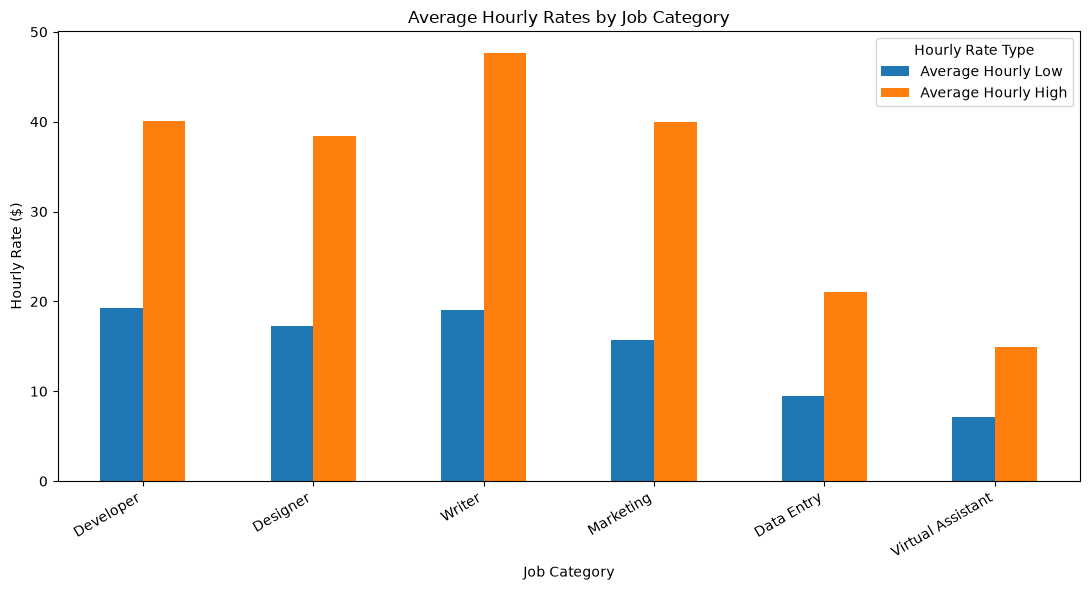

In [28]:
# Step 16: Job Category Salary Comparison

import matplotlib.pyplot as plt

keyword_analysis.plot(
    x="Job Category",
    y=["Average Hourly Low", "Average Hourly High"],
    kind="bar",
    figsize=(11, 6)
)

plt.title("Average Hourly Rates by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Hourly Rate ($)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Hourly Rate Type")
plt.tight_layout()
plt.show()

In [29]:
# Step 17: Monthly Job Posting Analysis

# Convert published_date to datetime
df["published_date"] = pd.to_datetime(
    df["published_date"],
    errors="coerce"
)

# Extract month and year
df["month"] = df["published_date"].dt.to_period("M")

# Count monthly job postings
monthly_jobs = (
    df.groupby("month")
    .size()
    .reset_index(name="Total Jobs")
)

print(monthly_jobs)

     month  Total Jobs
0  2023-11           1
1  2023-12          10
2  2024-01          96
3  2024-02      101887
4  2024-03      142834


C:\Users\mohit\AppData\Local\Temp\ipykernel_10612\358432339.py:10: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month"] = df["published_date"].dt.to_period("M")


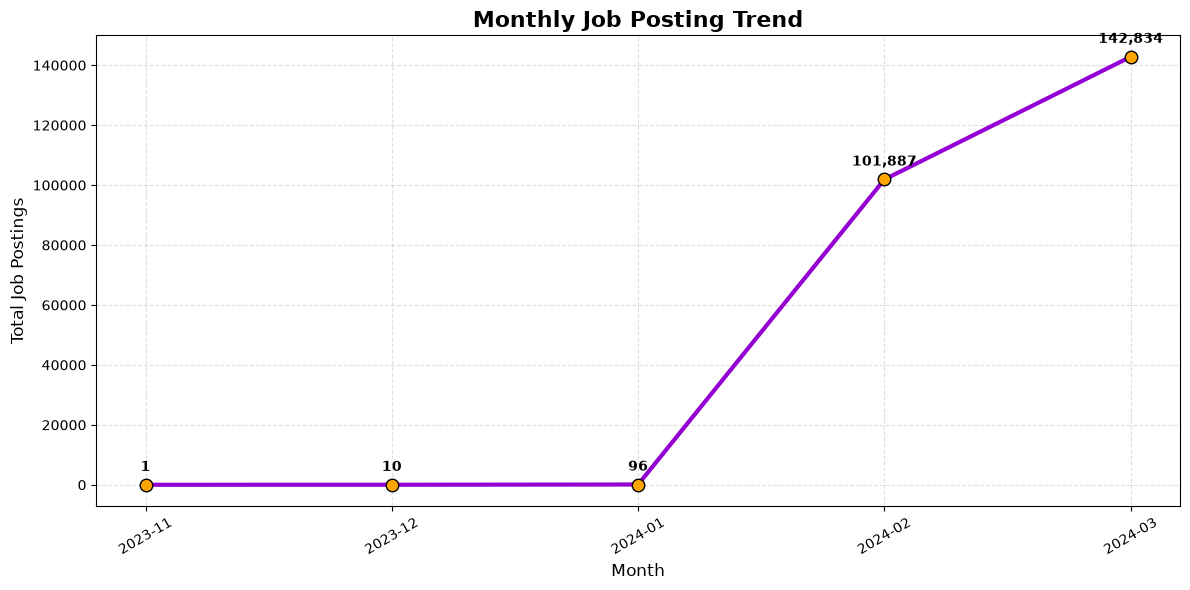

In [30]:
# Step 18: Colourful Monthly Job Posting Trend

import matplotlib.pyplot as plt

months = monthly_jobs["month"].astype(str)
jobs = monthly_jobs["Total Jobs"]

plt.figure(figsize=(12, 6))

plt.plot(
    months,
    jobs,
    marker="o",
    markersize=9,
    linewidth=3,
    color="darkviolet",
    markerfacecolor="orange",
    markeredgecolor="black"
)

# Show values on each point
for i, value in enumerate(jobs):
    plt.annotate(
        f"{value:,}",
        (i, value),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Monthly Job Posting Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Job Postings", fontsize=12)

plt.xticks(rotation=30)
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

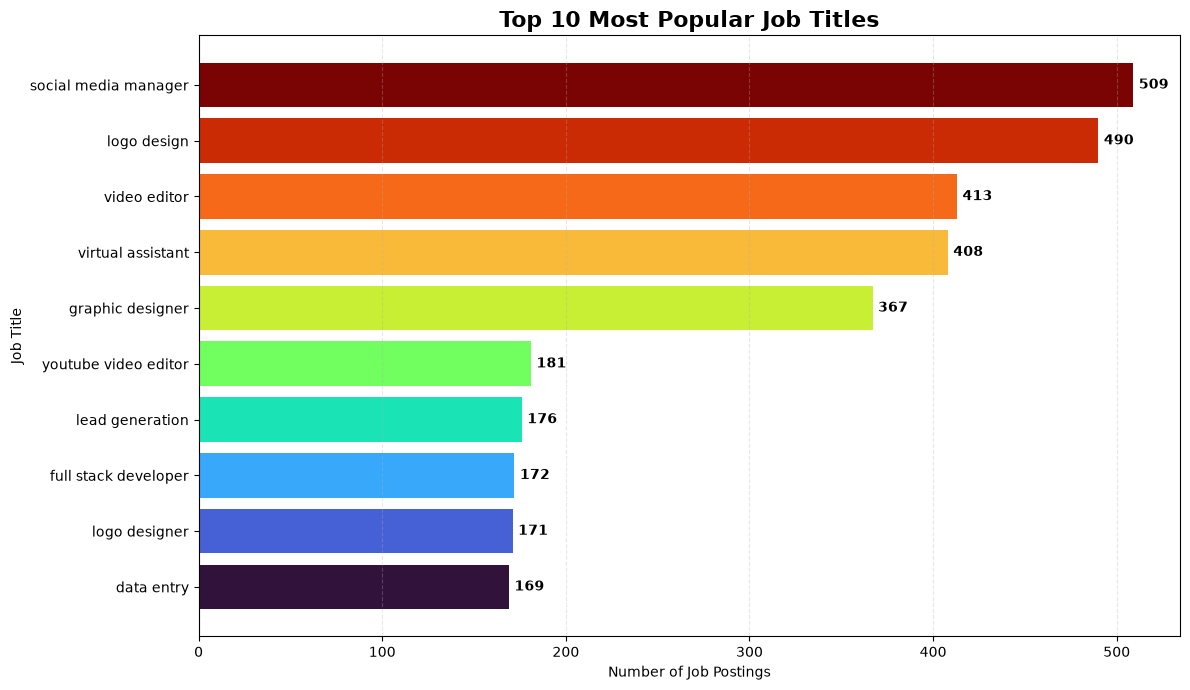

In [31]:
# Step 19: Top 10 Most Popular Job Titles

import matplotlib.pyplot as plt

top_jobs = df["title"].value_counts().head(10).sort_values()

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_jobs.index,
    top_jobs.values,
    color=plt.cm.turbo(
        [i / 9 for i in range(10)]
    )
)

# Add job counts to each bar
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center",
        fontweight="bold"
    )

plt.title(
    "Top 10 Most Popular Job Titles",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Job Postings")
plt.ylabel("Job Title")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\mohit\AppData\Local\Temp\ipykernel_10612\392680582.py:11: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  category_data["published_date"].dt.to_period("M").astype(str)


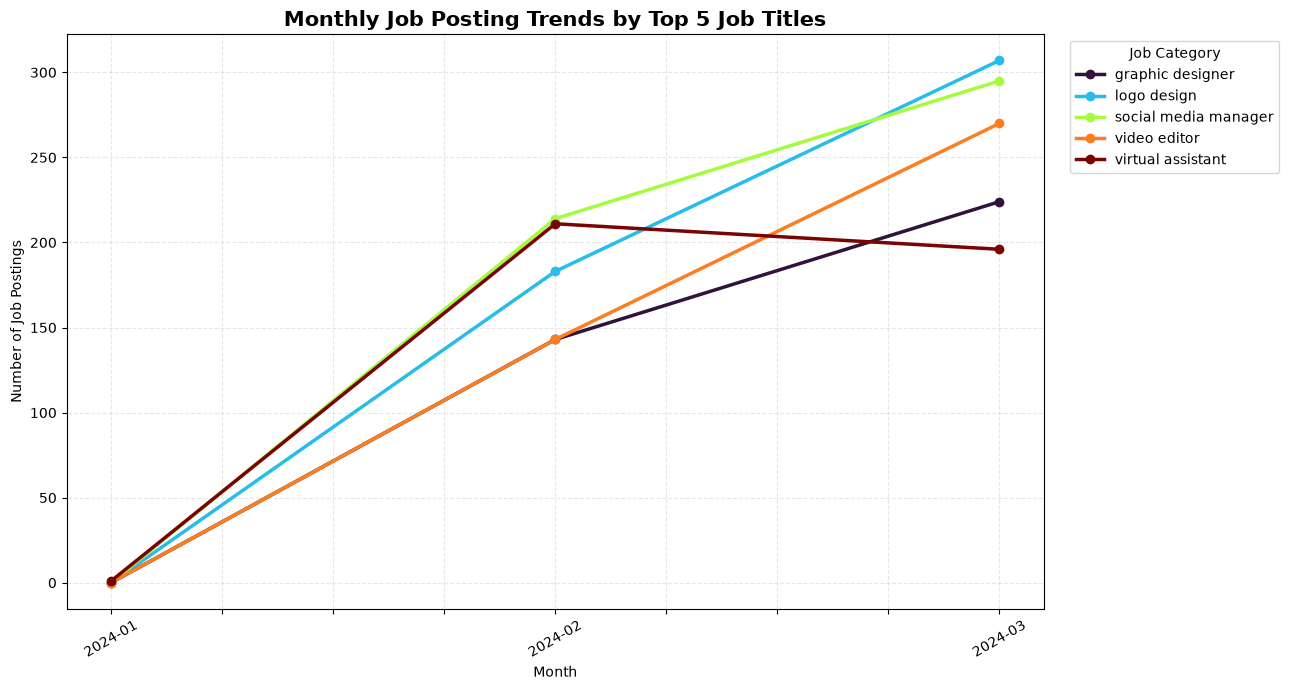

In [32]:
# Step 20: Monthly Job Category Trend

# Select top 5 job titles
top_5_titles = df["title"].value_counts().head(5).index

# Filter data for top 5 titles
category_data = df[df["title"].isin(top_5_titles)].copy()

# Extract month from published date
category_data["month"] = (
    category_data["published_date"].dt.to_period("M").astype(str)
)

# Count monthly postings for each title
monthly_category = category_data.groupby(
    ["month", "title"]
).size().unstack(fill_value=0)

# Colourful line chart
ax = monthly_category.plot(
    kind="line",
    marker="o",
    linewidth=2.5,
    figsize=(13, 7),
    colormap="turbo"
)

ax.set_title(
    "Monthly Job Posting Trends by Top 5 Job Titles",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Month")
ax.set_ylabel("Number of Job Postings")
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(title="Job Category", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

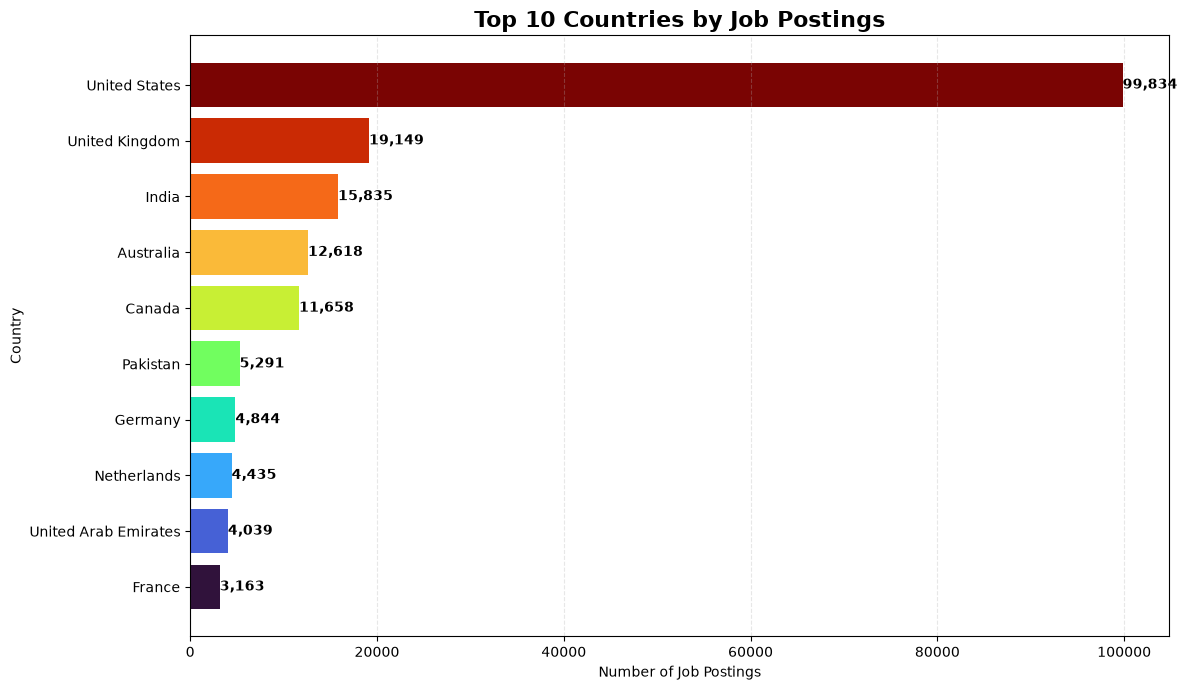

In [33]:
# Step 21: Country-wise Job Posting Analysis

import matplotlib.pyplot as plt

# Find top 10 countries
top_countries = (
    df["country"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

# Create colourful horizontal bar chart
plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_countries.index,
    top_countries.values,
    color=plt.cm.turbo(
        [i / (len(top_countries) - 1)
         for i in range(len(top_countries))]
    )
)

# Add values to bars
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center",
        fontweight="bold"
    )

plt.title(
    "Top 10 Countries by Job Postings",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Number of Job Postings")
plt.ylabel("Country")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

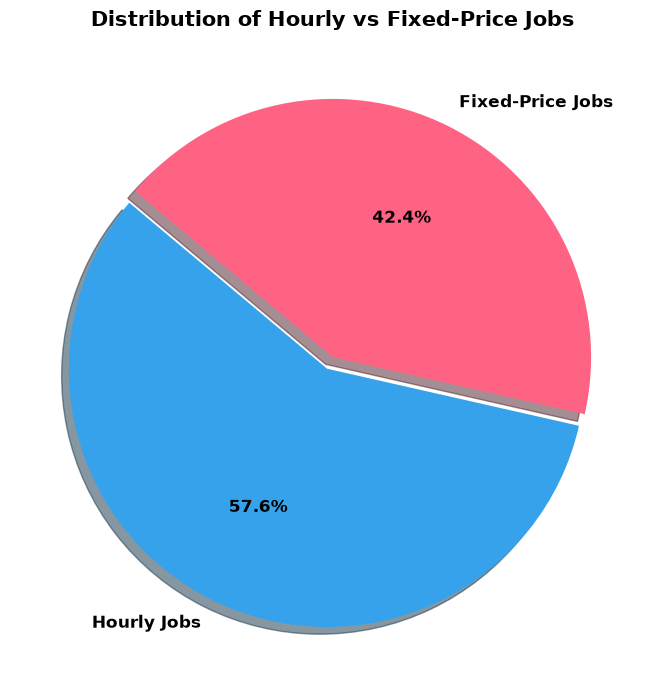

Hourly jobs: 140937
Fixed-price jobs: 103891


In [34]:
# Step 22: Hourly vs Fixed-Price Job Distribution

import matplotlib.pyplot as plt

# Count jobs by payment type
payment_counts = df["is_hourly"].value_counts().reindex(
    [True, False],
    fill_value=0
)

labels = ["Hourly Jobs", "Fixed-Price Jobs"]

plt.figure(figsize=(9, 7))

plt.pie(
    payment_counts.values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=140,
    colors=["#36A2EB", "#FF6384"],
    explode=(0.05, 0),
    shadow=True,
    textprops={"fontsize": 12, "fontweight": "bold"}
)

plt.title(
    "Distribution of Hourly vs Fixed-Price Jobs",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("Hourly jobs:", payment_counts.loc[True])
print("Fixed-price jobs:", payment_counts.loc[False])

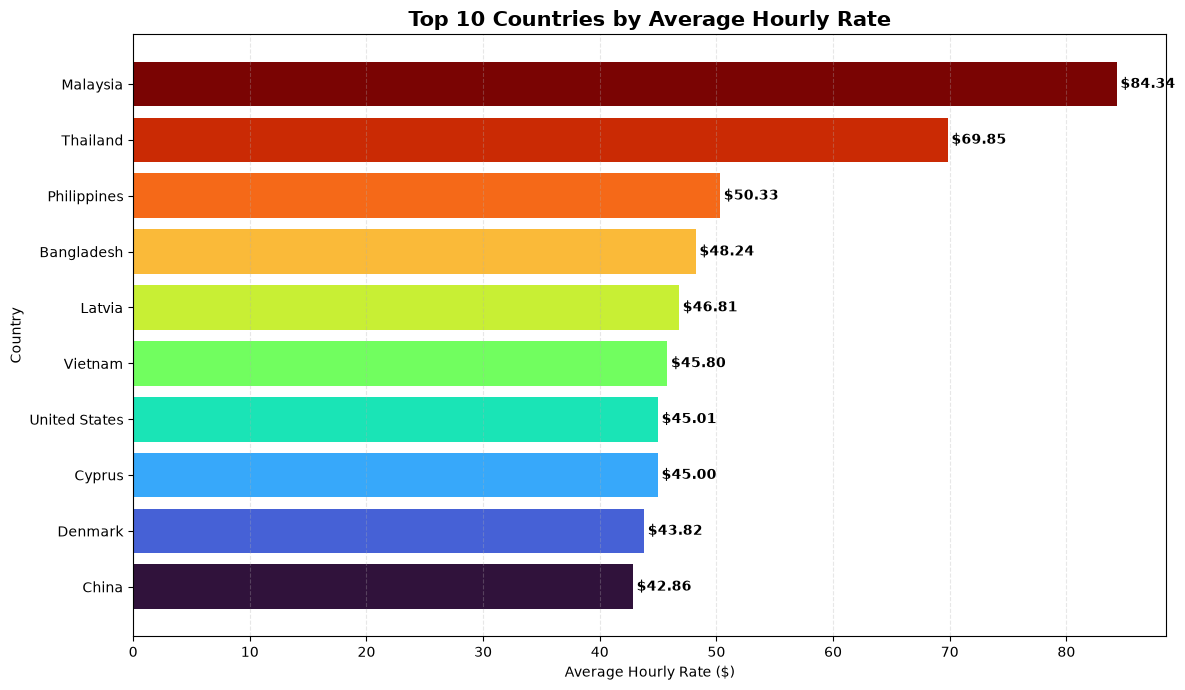

               Average_Hourly_Rate  Job_Count
country                                      
China                        42.86        397
Denmark                      43.82        407
Cyprus                       45.00        160
United States                45.01      46606
Vietnam                      45.80        250
Latvia                       46.81        106
Bangladesh                   48.24        733
Philippines                  50.33        902
Thailand                     69.85        287
Malaysia                     84.34        325


In [35]:
# Step 23: Top 10 Countries by Average Hourly Rate

import matplotlib.pyplot as plt

# Select hourly jobs with available rates
hourly_jobs = df[
    (df["is_hourly"] == True) &
    (df["hourly_high"].notna()) &
    (df["hourly_high"] < 999) &
    (df["country"].notna())
].copy()

# Calculate country-wise average rate and job count
country_rates = (
    hourly_jobs.groupby("country")
    .agg(
        Average_Hourly_Rate=("hourly_high", "mean"),
        Job_Count=("hourly_high", "count")
    )
)

# Keep countries with at least 100 jobs for a more reliable comparison
country_rates = country_rates[
    country_rates["Job_Count"] >= 100
]

# Select top 10 countries
top_country_rates = country_rates.nlargest(
    10, "Average_Hourly_Rate"
).sort_values("Average_Hourly_Rate")

# Colourful bar chart
plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_country_rates.index,
    top_country_rates["Average_Hourly_Rate"],
    color=plt.cm.turbo(
        [i / 9 for i in range(10)]
    )
)

# Add average rate labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"${width:.2f}",
        va="center",
        fontweight="bold"
    )

plt.title(
    "Top 10 Countries by Average Hourly Rate",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Average Hourly Rate ($)")
plt.ylabel("Country")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print(top_country_rates.round(2))

In [36]:
# Step 24: Prepare Data for Job Demand Prediction

import pandas as pd

# Find top 5 job categories
top_5_titles = df["title"].value_counts().head(5).index

# Filter top 5 categories
demand_df = df[df["title"].isin(top_5_titles)].copy()

# Extract month
demand_df["month"] = demand_df["published_date"].dt.to_period("M")

# Count jobs by month and category
demand_data = (
    demand_df.groupby(["month", "title"])
    .size()
    .reset_index(name="job_count")
)

print(demand_data.head(15))

      month                 title  job_count
0   2024-01     virtual assistant          1
1   2024-02      graphic designer        143
2   2024-02           logo design        183
3   2024-02  social media manager        214
4   2024-02          video editor        143
5   2024-02     virtual assistant        211
6   2024-03      graphic designer        224
7   2024-03           logo design        307
8   2024-03  social media manager        295
9   2024-03          video editor        270
10  2024-03     virtual assistant        196


C:\Users\mohit\AppData\Local\Temp\ipykernel_10612\461193589.py:12: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  demand_df["month"] = demand_df["published_date"].dt.to_period("M")


In [37]:
# Step 25: Prepare Features for Job Demand Prediction

from sklearn.preprocessing import LabelEncoder

# Copy the demand dataset
model_df = demand_data.copy()

# Convert month into numeric year and month features
model_df["month_date"] = model_df["month"].dt.to_timestamp()
model_df["year"] = model_df["month_date"].dt.year
model_df["month_number"] = model_df["month_date"].dt.month

# Encode job titles
encoder = LabelEncoder()
model_df["job_category"] = encoder.fit_transform(model_df["title"])

# Display prepared data
print(model_df[
    ["month", "title", "year", "month_number",
     "job_category", "job_count"]
])

      month                 title  year  month_number  job_category  job_count
0   2024-01     virtual assistant  2024             1             4          1
1   2024-02      graphic designer  2024             2             0        143
2   2024-02           logo design  2024             2             1        183
3   2024-02  social media manager  2024             2             2        214
4   2024-02          video editor  2024             2             3        143
5   2024-02     virtual assistant  2024             2             4        211
6   2024-03      graphic designer  2024             3             0        224
7   2024-03           logo design  2024             3             1        307
8   2024-03  social media manager  2024             3             2        295
9   2024-03          video editor  2024             3             3        270
10  2024-03     virtual assistant  2024             3             4        196


In [38]:
# Step 26: Prepare Features and Target

# Input features
X = model_df[["month_number", "job_category"]]

# Target: number of job postings
y = model_df["job_count"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Features shape: (11, 2)
Target shape: (11,)

Input Features:
   month_number  job_category
0             1             4
1             2             0
2             2             1
3             2             2
4             2             3

Target Values:
0      1
1    143
2    183
3    214
4    143
Name: job_count, dtype: int64


In [39]:
# Step 27: Train Random Forest Model

from sklearn.ensemble import RandomForestRegressor

# Create model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train model
model.fit(X, y)

print("Model training completed successfully!")
print("Training records:", len(X))

Model training completed successfully!
Training records: 11


In [40]:
# Step 28: Predict Job Demand for April 2024

# Prepare April 2024 input for all 5 job categories
future_data = pd.DataFrame({
    "month_number": [4, 4, 4, 4, 4],
    "job_category": [0, 1, 2, 3, 4]
})

# Predict job demand
future_data["Predicted Jobs"] = model.predict(future_data)

# Add job category names
future_data["Job Category"] = encoder.inverse_transform(
    future_data["job_category"]
)

# Sort by predicted demand
future_data = future_data.sort_values(
    by="Predicted Jobs",
    ascending=False
)

print("Predicted Job Demand for April 2024:")
print(
    future_data[
        ["Job Category", "Predicted Jobs"]
    ].round(0).to_string(index=False)
)

Predicted Job Demand for April 2024:
        Job Category  Predicted Jobs
social media manager           290.0
         logo design           281.0
        video editor           264.0
    graphic designer           242.0
   virtual assistant           202.0


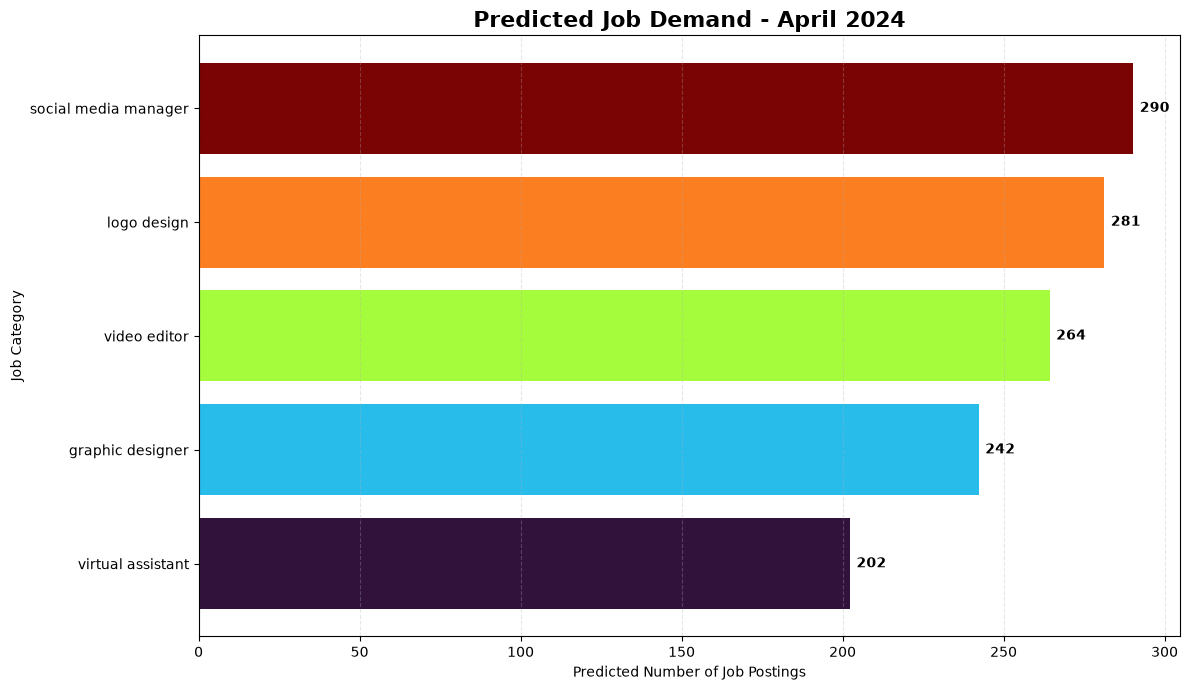

In [41]:
# Step 29: Visualize Predicted Job Demand

import matplotlib.pyplot as plt

chart_data = future_data.sort_values(
    by="Predicted Jobs",
    ascending=True
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    chart_data["Job Category"],
    chart_data["Predicted Jobs"],
    color=plt.cm.turbo(
        [i / (len(chart_data) - 1)
         for i in range(len(chart_data))]
    )
)

# Display prediction values
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.0f}",
        va="center",
        fontweight="bold"
    )

plt.title(
    "Predicted Job Demand - April 2024",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Predicted Number of Job Postings")
plt.ylabel("Job Category")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
# Step 30: Evaluate Random Forest Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict on training data
y_pred = model.predict(X)

# Calculate evaluation metrics
mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("R2 Score:", round(r2, 4))

Model Evaluation Results
------------------------
MAE: 22.16
MSE: 983.06
R2 Score: 0.8512


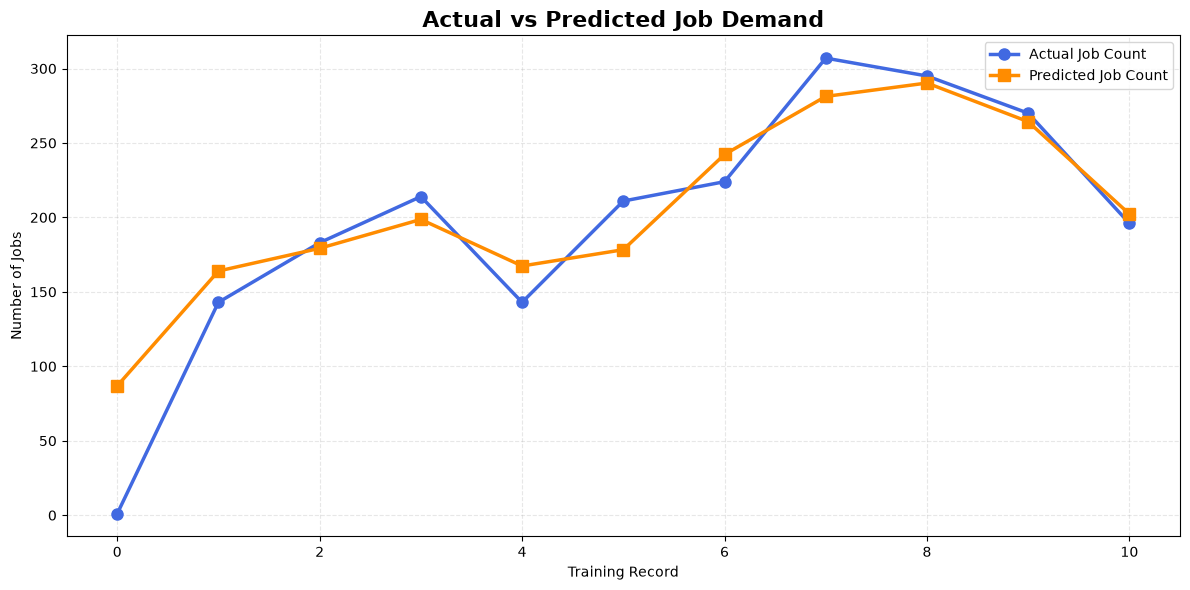

In [43]:
# Step 31: Actual vs Predicted Job Demand

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    range(len(y)),
    y.values,
    marker="o",
    linewidth=2.5,
    markersize=8,
    color="royalblue",
    label="Actual Job Count"
)

plt.plot(
    range(len(y_pred)),
    y_pred,
    marker="s",
    linewidth=2.5,
    markersize=8,
    color="darkorange",
    label="Predicted Job Count"
)

plt.title(
    "Actual vs Predicted Job Demand",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Training Record")
plt.ylabel("Number of Jobs")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
# Step 32: Prepare Job Titles for Recommendation System

# Remove rows with missing job titles
jobs_df = df.dropna(subset=["title"]).copy()

# Remove duplicate job titles for the title list
job_titles = jobs_df["title"].drop_duplicates()

print("Total job postings:", len(jobs_df))
print("Unique job titles:", len(job_titles))

print("\nSample Job Titles:")
print(job_titles.head(15).to_string(index=False))

Total job postings: 244827
Unique job titles: 201374

Sample Job Titles:
experienced media buyer for solar pannel and ro...
                              full stack developer
                                   smma bubble app
            talent hunter specialized in marketing
                                     data engineer
              seo for portuguese psychologist site
                  want to fix the wordpress plugin
need portuguese writers who can understand and ...
looker studio dashboard for leadgen and e-comme...
php/html/css wordpress developer needed for web...
3d designer needed to create a 3d model of a ch...
technical fashion designer with 3d skills for l...
                               affiliate marketing
urgent: fix emails not working on discourse ins...
                          us located so-me manager


In [45]:
# Step 33: Convert Job Titles into TF-IDF Features

from sklearn.feature_extraction.text import TfidfVectorizer

# Convert job titles into numerical features
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

job_tfidf = tfidf.fit_transform(
    jobs_df["title"].fillna("")
)

print("TF-IDF Matrix Shape:", job_tfidf.shape)
print("Total Job Titles:", len(jobs_df))
print("Total Features:", len(tfidf.get_feature_names_out()))

TF-IDF Matrix Shape: (244827, 5000)
Total Job Titles: 244827
Total Features: 5000


In [46]:
# Step 34: Job Recommendation Function

from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

def recommend_jobs(query, top_n=10):
    query_vector = tfidf.transform([query.lower()])

    similarities = cosine_similarity(query_vector, job_tfidf).flatten()

    top_indices = similarities.argsort()[::-1]

    recommendations = []
    seen_titles = set()

    for idx in top_indices:
        title = jobs_df.iloc[idx]["title"]

        if title not in seen_titles and similarities[idx] > 0:
            recommendations.append({
                "Job Title": title,
                "Similarity Score": round(similarities[idx], 3)
            })
            seen_titles.add(title)

        if len(recommendations) >= top_n:
            break

    return pd.DataFrame(recommendations)


# Test the recommendation system
recommendations = recommend_jobs("python developer", 10)

print("Recommended Jobs for: Python Developer")
print(recommendations.to_string(index=False))

Recommended Jobs for: Python Developer
                                Job Title  Similarity Score
                         python developer             1.000
                   anvil python developer             1.000
                   python and r developer             1.000
                        `python developer             1.000
               python developer (us only)             1.000
python developer with pypdf2, fillpdf etc             1.000
           orchestration python developer             1.000
                  python developer needed             0.884
        expert python, anaconda developer             0.875
                  expert python developer             0.875


In [47]:
# Step 35: Test Job Recommendations for Different Queries

test_queries = [
    "python developer",
    "graphic designer",
    "data analyst",
    "digital marketing"
]

for query in test_queries:
    print("\n" + "=" * 60)
    print(f"Recommended Jobs for: {query.title()}")
    print("=" * 60)

    result = recommend_jobs(query, 5)

    if result.empty:
        print("No matching jobs found.")
    else:
        print(result.to_string(index=False))


Recommended Jobs for: Python Developer
                 Job Title  Similarity Score
          python developer               1.0
    anvil python developer               1.0
    python and r developer               1.0
         `python developer               1.0
python developer (us only)               1.0

Recommended Jobs for: Graphic Designer
                                                  Job Title  Similarity Score
                                           graphic designer               1.0
                                       graphic designer....               1.0
                graphic designer in islamabad or rawalpindi               1.0
                                          graphic  designer               1.0
أريد حد يسويلي صورة حسب التعليمات المطلوبة graphic designer               1.0

Recommended Jobs for: Data Analyst
              Job Title  Similarity Score
           data analyst               1.0
  data analyst lecturer               1.0
    oncall data anal

In [48]:
# Step 36: Enhanced Job Recommendation System

from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

def recommend_jobs_details(query, top_n=10):

    query_vector = tfidf.transform([query.lower()])
    similarities = cosine_similarity(
        query_vector, job_tfidf
    ).flatten()

    top_indices = similarities.argsort()[::-1]

    recommendations = []
    seen_titles = set()

    for idx in top_indices:

        row = jobs_df.iloc[idx]
        title = row["title"]

        if title not in seen_titles and similarities[idx] > 0:

            recommendations.append({
                "Job Title": title,
                "Similarity Score": round(similarities[idx], 3),
                "Hourly": row["is_hourly"],
                "Hourly Rate Low": row["hourly_low"],
                "Hourly Rate High": row["hourly_high"],
                "Country": row["country"]
            })

            seen_titles.add(title)

        if len(recommendations) >= top_n:
            break

    return pd.DataFrame(recommendations)


# Test the enhanced recommendation system
result = recommend_jobs_details("python developer", 10)

print("Job Recommendations for Python Developer")
print(result.to_string(index=False))

Job Recommendations for Python Developer
                                Job Title  Similarity Score  Hourly  Hourly Rate Low  Hourly Rate High        Country
                         python developer             1.000   False              NaN               NaN          India
                   anvil python developer             1.000    True              NaN               NaN  United States
                   python and r developer             1.000    True             25.0              30.0  United States
                        `python developer             1.000    True              NaN               NaN United Kingdom
               python developer (us only)             1.000    True             50.0              80.0  United States
python developer with pypdf2, fillpdf etc             1.000    True              NaN               NaN  United States
           orchestration python developer             1.000    True              5.0               7.0          India
               

In [ ]:
# Step 37: Interactive Job Recommendation System

user_query = input(
    "Enter your skills or preferred job role: "
)

result = recommend_jobs_details(user_query, 10)

if result.empty:
    print("\nNo matching jobs found. Try different keywords.")
else:
    print(f"\nTop Job Recommendations for: {user_query}")
    print("-" * 80)

    display_columns = [
        "Job Title",
        "Similarity Score",
        "Hourly Rate Low",
        "Hourly Rate High",
        "Country"
    ]

    print(result[display_columns].to_string(index=False))

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 21)

In [50]:
# Step 37: Fast Job Recommendation System

import numpy as np

def recommend_jobs_details(query, top_n=10):

    query_vector = tfidf.transform([query.lower()])

    # Calculate similarity without processing a full matrix
    scores = (job_tfidf @ query_vector.T).toarray().flatten()

    # Select only the top matching results
    top_indices = np.argpartition(
        scores, -min(top_n, len(scores))
    )[-min(top_n, len(scores)):]

    top_indices = top_indices[np.argsort(scores[top_indices])[::-1]]

    recommendations = []
    seen_titles = set()

    for idx in top_indices:
        row = jobs_df.iloc[idx]
        title = row["title"]

        if scores[idx] > 0 and title not in seen_titles:
            recommendations.append({
                "Job Title": title,
                "Similarity Score": round(float(scores[idx]), 3),
                "Hourly": row["is_hourly"],
                "Hourly Rate Low": row["hourly_low"],
                "Hourly Rate High": row["hourly_high"],
                "Country": row["country"]
            })
            seen_titles.add(title)

    return pd.DataFrame(recommendations)


# Test
result = recommend_jobs_details("python developer", 10)
print(result.to_string(index=False))

       Job Title  Similarity Score  Hourly  Hourly Rate Low  Hourly Rate High Country
python developer               1.0   False              NaN               NaN   India


In [52]:
# Step 38: Diagnose Recommendation Results

query_vector = tfidf.transform(["python developer"])
scores = (job_tfidf @ query_vector.T).toarray().flatten()

print("Total job postings:", len(jobs_df))
print("Matching postings:", (scores > 0).sum())
print("Unique matching titles:", jobs_df.loc[scores > 0, "title"].nunique())
print("Highest similarity score:", scores.max())

Total job postings: 244827
Matching postings: 17472
Unique matching titles: 13398
Highest similarity score: 1.0000000000000002


In [53]:
# Step 39: Fix Top 10 Job Recommendations

query = "python developer"
top_n = 10

query_vector = tfidf.transform([query.lower()])
scores = (job_tfidf @ query_vector.T).toarray().flatten()

# Keep only matching jobs
matching_indices = np.where(scores > 0)[0]

# Sort matching jobs by similarity score
matching_indices = matching_indices[
    np.argsort(scores[matching_indices])[::-1]
]

recommendations = []
seen_titles = set()

for idx in matching_indices:
    row = jobs_df.iloc[idx]
    title = row["title"]

    if title not in seen_titles:
        recommendations.append({
            "Job Title": title,
            "Similarity Score": round(float(scores[idx]), 3),
            "Hourly": row["is_hourly"],
            "Hourly Rate Low": row["hourly_low"],
            "Hourly Rate High": row["hourly_high"],
            "Country": row["country"]
        })

        seen_titles.add(title)

    if len(recommendations) >= top_n:
        break

result = pd.DataFrame(recommendations)

print("Job Recommendations for:", query.title())
print(result.to_string(index=False))

Job Recommendations for: Python Developer
                                Job Title  Similarity Score  Hourly  Hourly Rate Low  Hourly Rate High        Country
                         python developer             1.000   False              NaN               NaN  United States
           orchestration python developer             1.000    True              5.0               7.0          India
                        `python developer             1.000    True              NaN               NaN United Kingdom
                   anvil python developer             1.000    True              NaN               NaN  United States
                   python and r developer             1.000    True             25.0              30.0  United States
               python developer (us only)             1.000    True             50.0              80.0  United States
python developer with pypdf2, fillpdf etc             1.000    True              NaN               NaN  United States
              

In [54]:
# Step 40: Prepare Monthly Job Market Dashboard Data

import pandas as pd

# Create a separate dashboard dataframe
dashboard_df = df.copy()

# Convert published date to datetime
dashboard_df["published_date"] = pd.to_datetime(
    dashboard_df["published_date"], errors="coerce"
)

# Extract month
dashboard_df["month"] = (
    dashboard_df["published_date"].dt.to_period("M").astype(str)
)

# Monthly job posting count
monthly_jobs = (
    dashboard_df.groupby("month")
    .size()
    .reset_index(name="Total Jobs")
)

# Monthly payment type distribution
payment_trend = (
    dashboard_df.groupby(["month", "is_hourly"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={True: "Hourly Jobs", False: "Fixed-Price Jobs"})
    .reset_index()
)

print("MONTHLY JOB POSTINGS")
print(monthly_jobs.to_string(index=False))

print("\nMONTHLY PAYMENT TYPE DISTRIBUTION")
print(payment_trend.to_string(index=False))

C:\Users\mohit\AppData\Local\Temp\ipykernel_10612\1457703835.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  dashboard_df["published_date"].dt.to_period("M").astype(str)


MONTHLY JOB POSTINGS
  month  Total Jobs
2023-11           1
2023-12          10
2024-01          96
2024-02      101887
2024-03      142834

MONTHLY PAYMENT TYPE DISTRIBUTION
  month  Fixed-Price Jobs  Hourly Jobs
2023-11                 0            1
2023-12                 2            8
2024-01                32           64
2024-02             42407        59480
2024-03             61450        81384


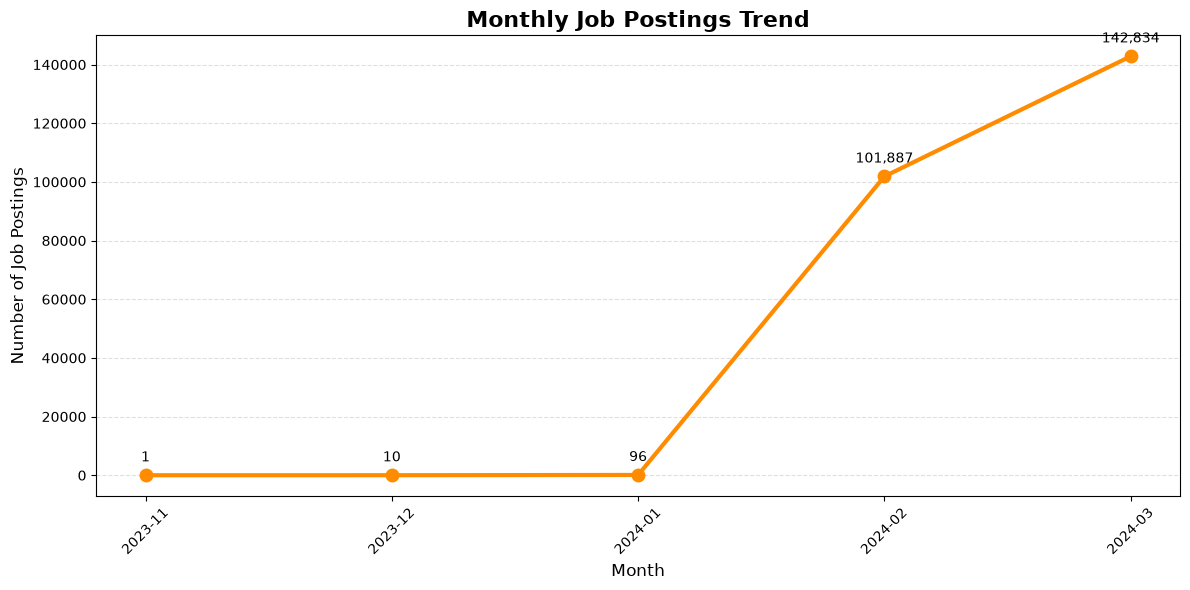

In [55]:
# Step 41: Monthly Job Postings Trend

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_jobs["month"],
    monthly_jobs["Total Jobs"],
    marker="o",
    linewidth=3,
    markersize=9,
    color="darkorange"
)

# Add values above each point
for i, row in monthly_jobs.iterrows():
    plt.annotate(
        f'{row["Total Jobs"]:,}',
        (i, row["Total Jobs"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10
    )

plt.title(
    "Monthly Job Postings Trend",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Job Postings", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

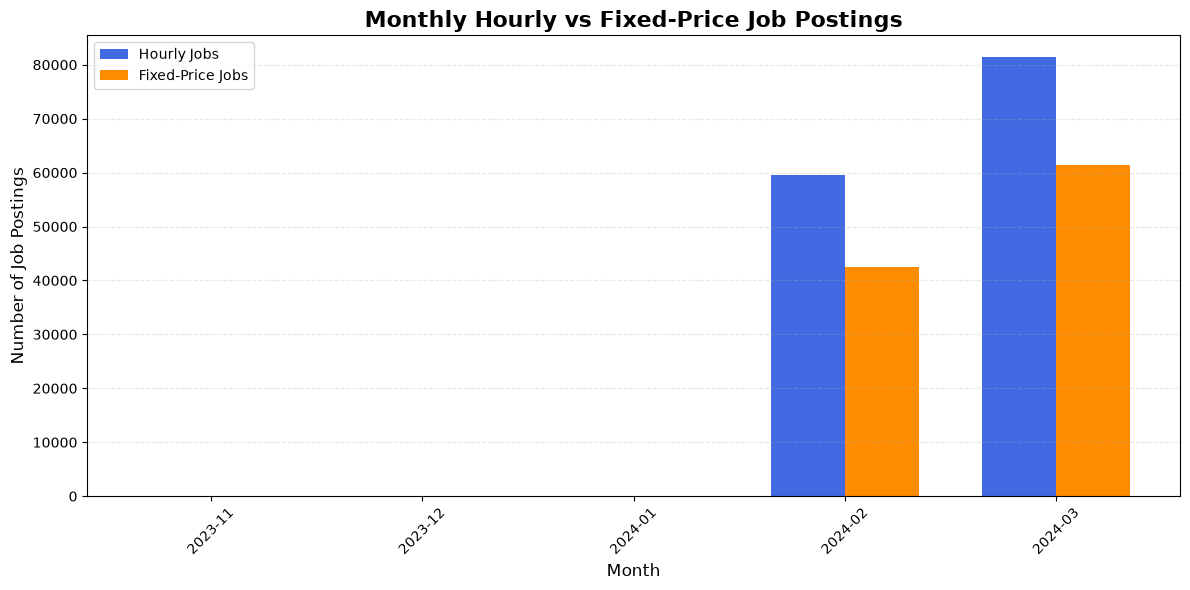

In [56]:
# Step 42: Monthly Hourly vs Fixed-Price Jobs

import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(payment_trend))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    payment_trend["Hourly Jobs"],
    width,
    label="Hourly Jobs",
    color="royalblue"
)

plt.bar(
    x + width / 2,
    payment_trend["Fixed-Price Jobs"],
    width,
    label="Fixed-Price Jobs",
    color="darkorange"
)

plt.title(
    "Monthly Hourly vs Fixed-Price Job Postings",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Job Postings", fontsize=12)

plt.xticks(x, payment_trend["month"], rotation=45)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [57]:
# Step 43: Monthly Payment Type Percentage

payment_percentage = payment_trend.copy()

payment_percentage["Total Jobs"] = (
    payment_percentage["Hourly Jobs"]
    + payment_percentage["Fixed-Price Jobs"]
)

payment_percentage["Hourly Jobs %"] = (
    payment_percentage["Hourly Jobs"]
    / payment_percentage["Total Jobs"] * 100
).round(2)

payment_percentage["Fixed-Price Jobs %"] = (
    payment_percentage["Fixed-Price Jobs"]
    / payment_percentage["Total Jobs"] * 100
).round(2)

print("MONTHLY PAYMENT TYPE PERCENTAGE")
print(
    payment_percentage[
        [
            "month",
            "Hourly Jobs %",
            "Fixed-Price Jobs %"
        ]
    ].to_string(index=False)
)

MONTHLY PAYMENT TYPE PERCENTAGE
  month  Hourly Jobs %  Fixed-Price Jobs %
2023-11         100.00                0.00
2023-12          80.00               20.00
2024-01          66.67               33.33
2024-02          58.38               41.62
2024-03          56.98               43.02


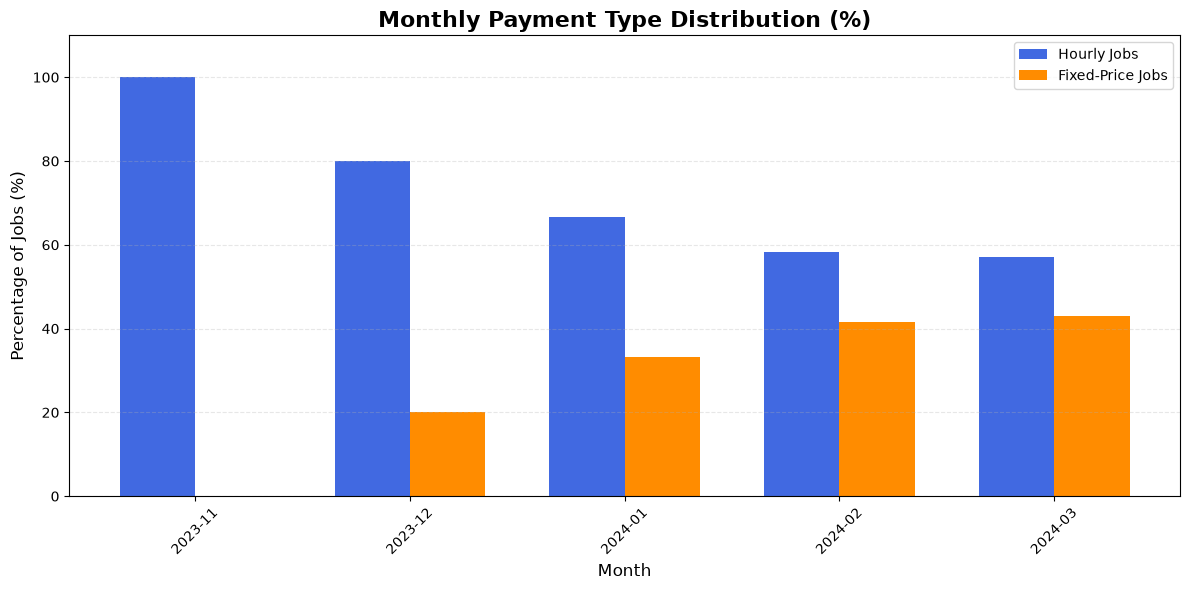

In [58]:
# Step 44: Monthly Payment Type Percentage Chart

import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(payment_percentage))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    payment_percentage["Hourly Jobs %"],
    width,
    label="Hourly Jobs",
    color="royalblue"
)

plt.bar(
    x + width / 2,
    payment_percentage["Fixed-Price Jobs %"],
    width,
    label="Fixed-Price Jobs",
    color="darkorange"
)

plt.title(
    "Monthly Payment Type Distribution (%)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Percentage of Jobs (%)", fontsize=12)

plt.xticks(x, payment_percentage["month"], rotation=45)
plt.ylim(0, 110)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

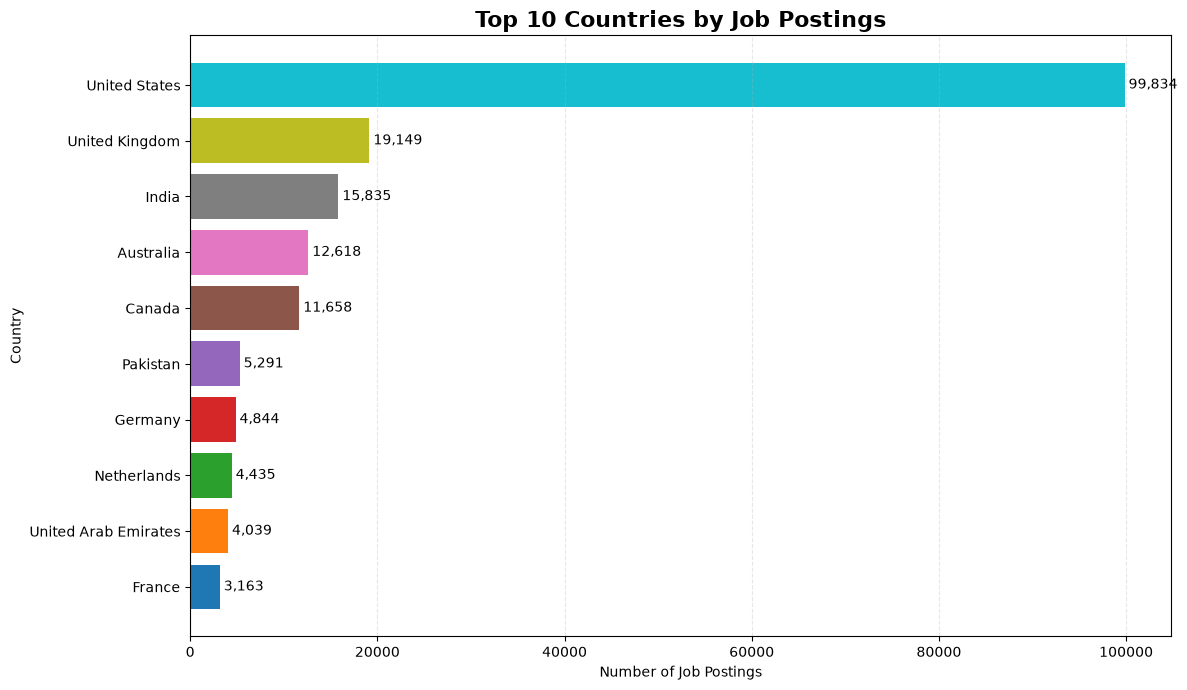

In [59]:
# Step 45: Top 10 Countries by Job Postings

import matplotlib.pyplot as plt

country_jobs = (
    df.dropna(subset=["country"])
    .groupby("country")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    country_jobs.index,
    country_jobs.values,
    color=plt.cm.tab10(range(len(country_jobs)))
)

# Add posting counts
for bar in bars:
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {int(bar.get_width()):,}",
        va="center",
        fontsize=10
    )

plt.title(
    "Top 10 Countries by Job Postings",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Job Postings")
plt.ylabel("Country")
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

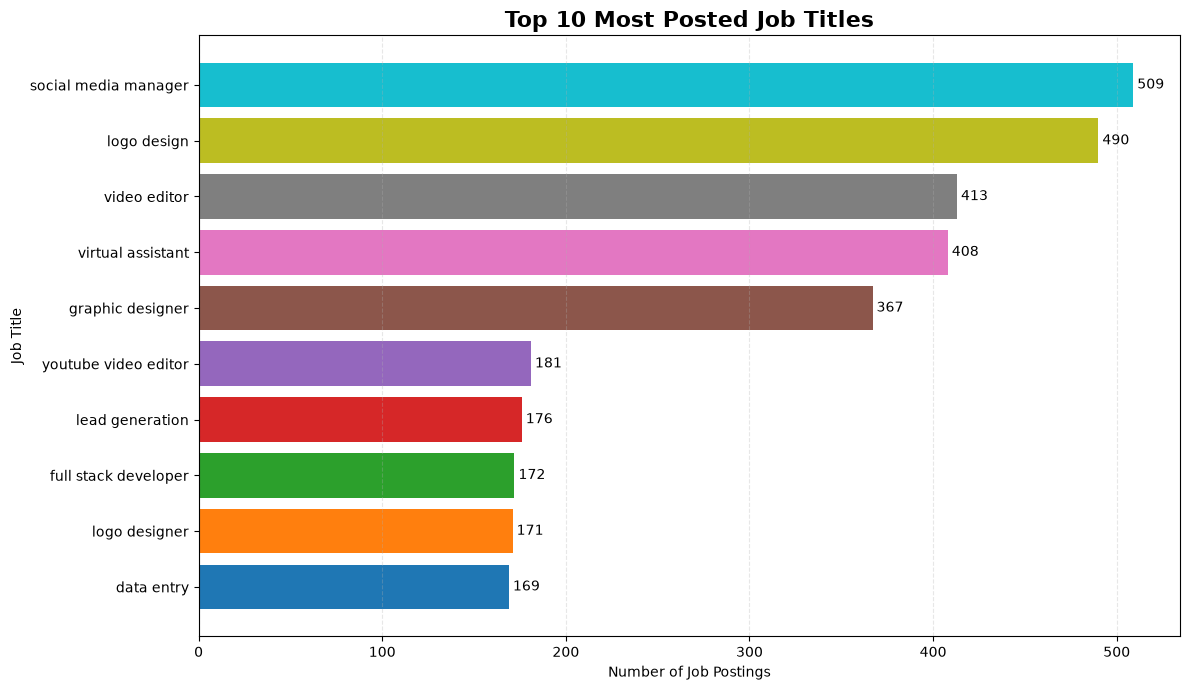

In [60]:
# Step 46: Top 10 Job Titles

import matplotlib.pyplot as plt

top_jobs = (
    df["title"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_jobs.index,
    top_jobs.values,
    color=plt.cm.tab10(range(len(top_jobs)))
)

for bar in bars:
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {int(bar.get_width()):,}",
        va="center",
        fontsize=10
    )

plt.title(
    "Top 10 Most Posted Job Titles",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Job Postings")
plt.ylabel("Job Title")
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

C:\Users\mohit\AppData\Local\Temp\ipykernel_10612\27738463.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  category_df["published_date"].dt.to_period("M").astype(str)


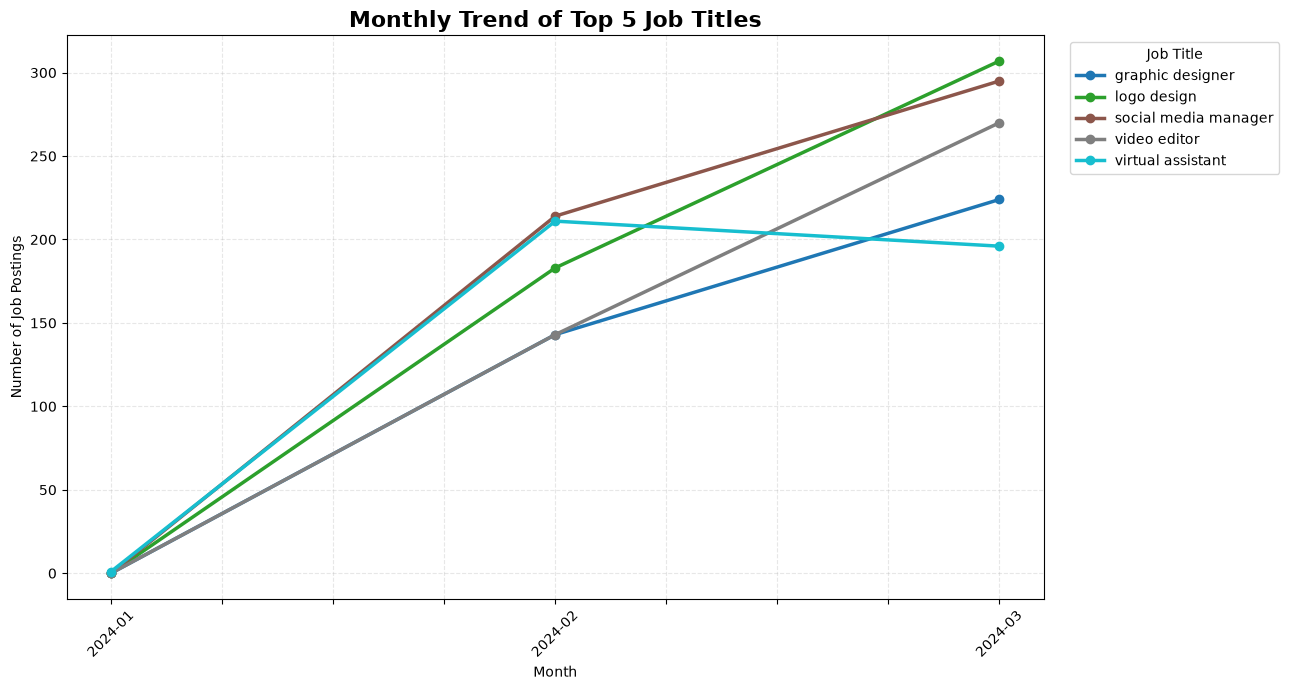

In [61]:
# Step 47: Monthly Comparison of Top 5 Job Titles

import pandas as pd
import matplotlib.pyplot as plt

# Extract month
category_df = df.dropna(subset=["title"]).copy()

category_df["published_date"] = pd.to_datetime(
    category_df["published_date"],
    errors="coerce"
)

category_df["month"] = (
    category_df["published_date"].dt.to_period("M").astype(str)
)

# Find top 5 job titles overall
top_5_titles = category_df["title"].value_counts().head(5).index

# Monthly counts for top 5 titles
monthly_category = (
    category_df[category_df["title"].isin(top_5_titles)]
    .groupby(["month", "title"])
    .size()
    .unstack(fill_value=0)
)

# Colourful line chart
monthly_category.plot(
    kind="line",
    marker="o",
    linewidth=2.5,
    figsize=(13, 7),
    colormap="tab10"
)

plt.title(
    "Monthly Trend of Top 5 Job Titles",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend(title="Job Title", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [62]:
# Step 48: Monthly Job Market Summary

monthly_summary = monthly_jobs.merge(
    payment_trend,
    on="month",
    how="left"
)

monthly_summary["Hourly Jobs %"] = (
    monthly_summary["Hourly Jobs"]
    / monthly_summary["Total Jobs"] * 100
).round(2)

monthly_summary["Fixed-Price Jobs %"] = (
    monthly_summary["Fixed-Price Jobs"]
    / monthly_summary["Total Jobs"] * 100
).round(2)

print("MONTHLY JOB MARKET SUMMARY")
print("=" * 90)

print(
    monthly_summary[
        [
            "month",
            "Total Jobs",
            "Hourly Jobs",
            "Fixed-Price Jobs",
            "Hourly Jobs %",
            "Fixed-Price Jobs %"
        ]
    ].to_string(index=False)
)

MONTHLY JOB MARKET SUMMARY
  month  Total Jobs  Hourly Jobs  Fixed-Price Jobs  Hourly Jobs %  Fixed-Price Jobs %
2023-11           1            1                 0         100.00                0.00
2023-12          10            8                 2          80.00               20.00
2024-01          96           64                32          66.67               33.33
2024-02      101887        59480             42407          58.38               41.62
2024-03      142834        81384             61450          56.98               43.02


In [63]:
# Step 49: Job Market Dashboard KPIs

total_jobs = len(df)
unique_titles = df["title"].nunique()
unique_countries = df["country"].nunique()

hourly_jobs_count = (df["is_hourly"] == True).sum()
fixed_jobs_count = (df["is_hourly"] == False).sum()

hourly_percentage = round(
    hourly_jobs_count / total_jobs * 100, 2
)

fixed_percentage = round(
    fixed_jobs_count / total_jobs * 100, 2
)

print("=" * 45)
print("       JOB MARKET DASHBOARD KPIs")
print("=" * 45)

print(f"Total Job Postings       : {total_jobs:,}")
print(f"Unique Job Titles        : {unique_titles:,}")
print(f"Countries Represented    : {unique_countries:,}")
print(f"Hourly Jobs              : {hourly_jobs_count:,}")
print(f"Fixed-Price Jobs         : {fixed_jobs_count:,}")
print(f"Hourly Jobs Percentage   : {hourly_percentage}%")
print(f"Fixed-Price Percentage   : {fixed_percentage}%")

print("=" * 45)

       JOB MARKET DASHBOARD KPIs
Total Job Postings       : 244,828
Unique Job Titles        : 201,374
Countries Represented    : 212
Hourly Jobs              : 140,937
Fixed-Price Jobs         : 103,891
Hourly Jobs Percentage   : 57.57%
Fixed-Price Percentage   : 42.43%


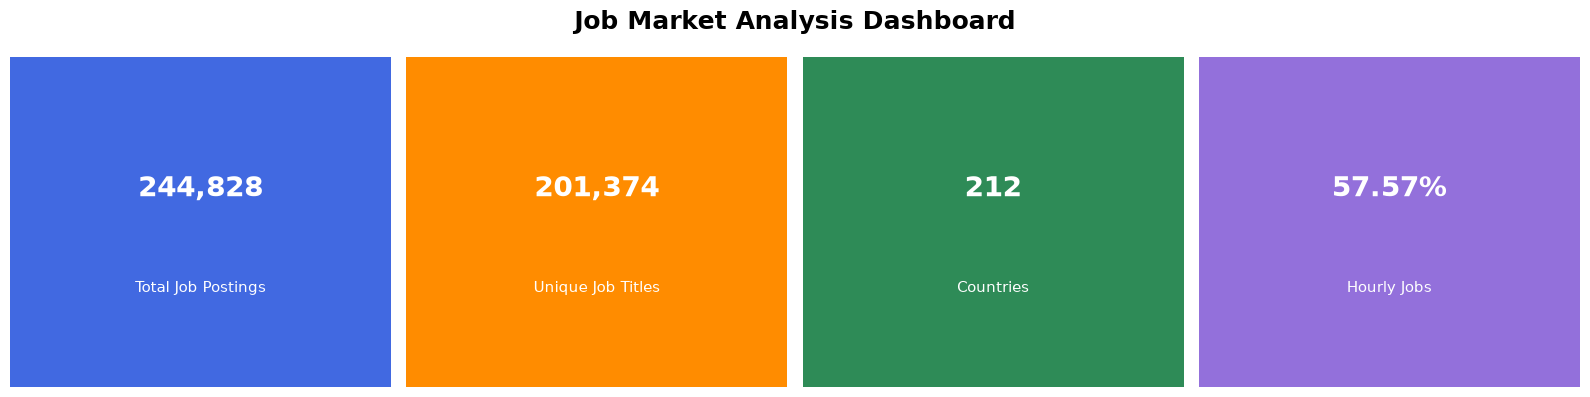

In [64]:
# Step 50: Visual KPI Dashboard

import matplotlib.pyplot as plt

kpi_labels = [
    "Total Job Postings",
    "Unique Job Titles",
    "Countries",
    "Hourly Jobs"
]

kpi_values = [
    f"{total_jobs:,}",
    f"{unique_titles:,}",
    f"{unique_countries:,}",
    f"{hourly_percentage}%"
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

colors = ["royalblue", "darkorange", "seagreen", "mediumpurple"]

for ax, label, value, color in zip(
    axes, kpi_labels, kpi_values, colors
):
    ax.set_facecolor(color)
    ax.text(
        0.5, 0.60, value,
        ha="center", va="center",
        fontsize=20, fontweight="bold", color="white"
    )
    ax.text(
        0.5, 0.30, label,
        ha="center", va="center",
        fontsize=11, color="white"
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "Job Market Analysis Dashboard",
    fontsize=18, fontweight="bold"
)

plt.tight_layout()
plt.show()

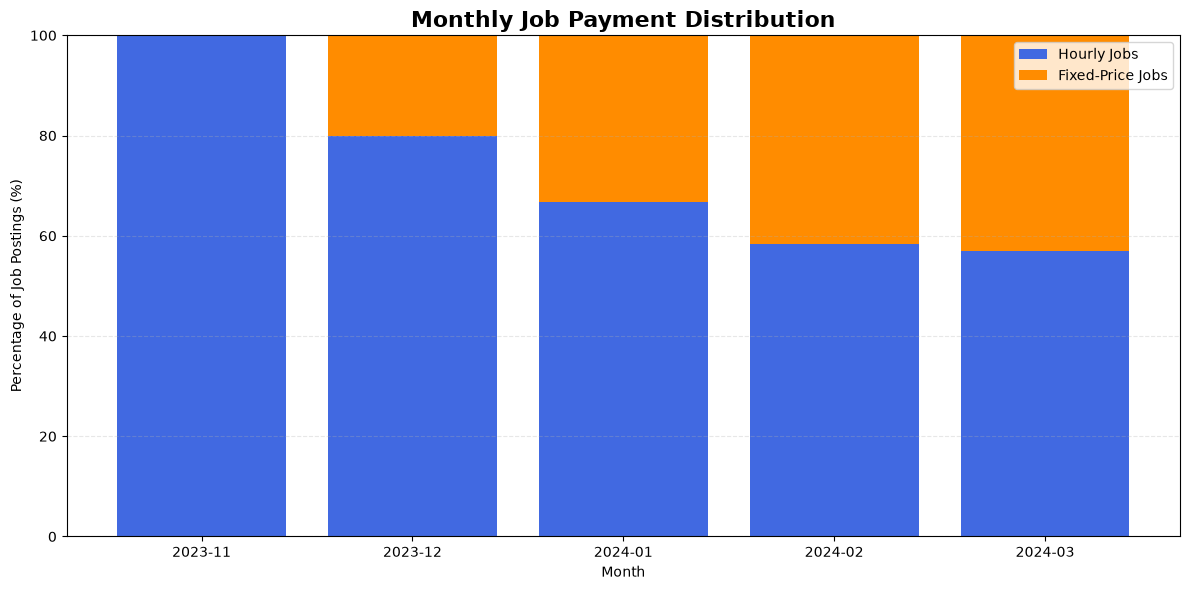

In [65]:
# Step 51: Monthly Payment Distribution - 100% Stacked Bar Chart

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    payment_percentage["month"],
    payment_percentage["Hourly Jobs %"],
    label="Hourly Jobs",
    color="royalblue"
)

plt.bar(
    payment_percentage["month"],
    payment_percentage["Fixed-Price Jobs %"],
    bottom=payment_percentage["Hourly Jobs %"],
    label="Fixed-Price Jobs",
    color="darkorange"
)

plt.title(
    "Monthly Job Payment Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Percentage of Job Postings (%)")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [66]:
# Step 52: Monthly Job Posting Growth Analysis

monthly_growth = monthly_jobs.copy()

monthly_growth["Growth %"] = (
    monthly_growth["Total Jobs"].pct_change() * 100
).round(2)

print("MONTHLY JOB POSTING GROWTH")
print("=" * 50)
print(monthly_growth.to_string(index=False))

# February to March growth
feb_jobs = monthly_growth.loc[
    monthly_growth["month"] == "2024-02", "Total Jobs"
].iloc[0]

mar_jobs = monthly_growth.loc[
    monthly_growth["month"] == "2024-03", "Total Jobs"
].iloc[0]

growth = ((mar_jobs - feb_jobs) / feb_jobs) * 100

print(f"\nFebruary to March Growth: {growth:.2f}%")

MONTHLY JOB POSTING GROWTH
  month  Total Jobs  Growth %
2023-11           1       NaN
2023-12          10    900.00
2024-01          96    860.00
2024-02      101887 106032.29
2024-03      142834     40.19

February to March Growth: 40.19%


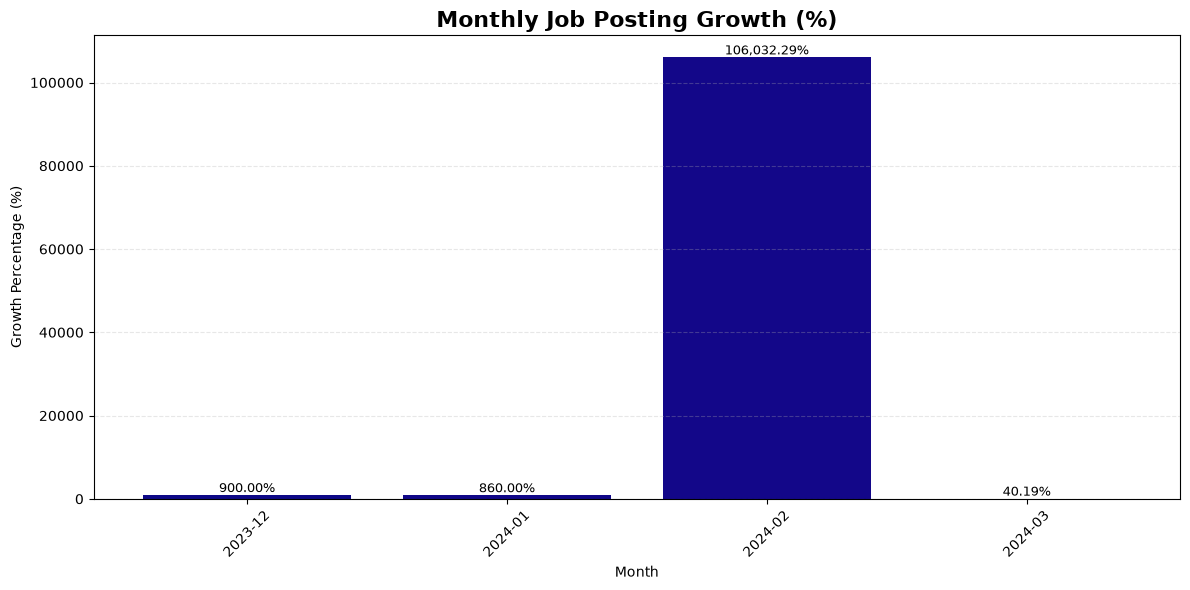

In [67]:
# Step 53: Monthly Job Posting Growth Chart

import matplotlib.pyplot as plt

growth_df = monthly_growth.dropna(subset=["Growth %"])

plt.figure(figsize=(12, 6))

bars = plt.bar(
    growth_df["month"],
    growth_df["Growth %"],
    color=plt.cm.plasma(
        range(len(growth_df))
    )
)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title(
    "Monthly Job Posting Growth (%)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Growth Percentage (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [68]:
# Step 54: Check Remote Work Related Columns

print("Dataset Columns:")
print(df.columns.tolist())

remote_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in ["remote", "work_mode", "location_type"])
]

print("\nRemote-work related columns:")
print(remote_columns if remote_columns else "No direct remote-work column found.")

Dataset Columns:
['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country', 'month']

Remote-work related columns:
No direct remote-work column found.


In [70]:
# Step 56: Verify Recommendation System Components

required_variables = [
    "df",
    "jobs_df",
    "tfidf",
    "job_tfidf"
]

for variable in required_variables:
    if variable in globals():
        print(f"{variable}: Available")
    else:
        print(f"{variable}: Missing")

df: Available
jobs_df: Available
tfidf: Available
job_tfidf: Available


In [72]:
# Step 58: Save Flask Recommendation Files

import os
import joblib

os.makedirs("job_market_model", exist_ok=True)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf,
    "job_market_model/tfidf_vectorizer.pkl"
)

# Save job information
jobs_df[
    ["title", "is_hourly", "hourly_low", "hourly_high", "country"]
].to_pickle(
    "job_market_model/jobs_data.pkl"
)

print("Files saved successfully!")

print("1. tfidf_vectorizer.pkl")
print("2. jobs_data.pkl")

Files saved successfully!
1. tfidf_vectorizer.pkl
2. jobs_data.pkl


In [73]:
# Step 59: Flask Application

from flask import Flask, render_template, request
import pandas as pd
import joblib
import os

app = Flask(__name__)

# Model folder
MODEL_DIR = "job_market_model"

# Load saved files
tfidf = joblib.load(
    os.path.join(MODEL_DIR, "tfidf_vectorizer.pkl")
)

jobs_df = pd.read_pickle(
    os.path.join(MODEL_DIR, "jobs_data.pkl")
)

@app.route("/", methods=["GET", "POST"])
def home():

    recommendations = pd.DataFrame()
    query = ""

    if request.method == "POST":
        query = request.form.get("query", "").strip()

        if query:
            query_vector = tfidf.transform([query.lower()])

            # Find jobs using title text similarity
            scores = (
                jobs_df["title"].fillna("").apply(
                    lambda title: title.lower()
                )
            )

            # Basic keyword matching for initial app testing
            matching_jobs = jobs_df[
                scores.str.contains(query.lower(), regex=False)
            ]

            recommendations = matching_jobs.head(10)

    return render_template(
        "index.html",
        recommendations=recommendations.to_dict("records"),
        query=query
    )

if __name__ == "__main__":
    app.run(debug=True)

 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
 * Restarting with stat


SystemExit: 1

C:\Users\mohit\AppData\Roaming\Python\Python311\site-packages\IPython\core\interactiveshell.py:3783: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)
